--- Fit Results for 100% Glycerol $T_1$ Recovery ---
Calculated T1: 18.67 ± 0.21 ms
Fitted plateau (a): 5.40 ± 0.08 V
Fitted amplitude (k): 13.15 ± 0.07 V



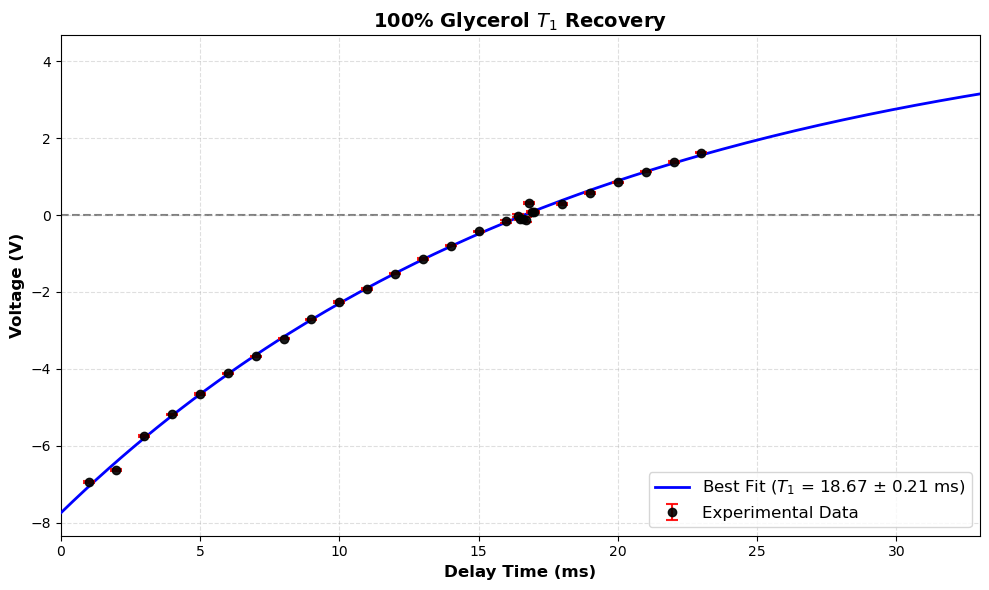

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def process_and_plot(filename, title):
    # 1. Load and Clean Data
    data = pd.read_csv(filename, encoding='windows-1252')
    data = data.iloc[:, 0:3].dropna()

    # Extract columns
    t = data.iloc[:, 0].values        
    V = data.iloc[:, 1].values   

    # Extract 3rd column (Standard Deviation) and convert mV to V
    std_dev = data.iloc[:, 2].values / 1000 
    std_dev = np.where(std_dev == 0, 1e-9, std_dev) # Prevent divide-by-zero errors

    # 2. Define the Mathematical Model
    def recovery_model(t, a, k, T1):
        return a - k * np.exp(-t / T1)

    # 3. Initial Guesses and Bounds
    p0 = [7.0, 14.0, 108.0]
    bounds = ([0, 0, 0], [20, 30, 300])

    # 4. Perform the Curve Fit
    popt, pcov = curve_fit(
        recovery_model, t, V, 
        p0=p0, 
        sigma=std_dev, 
        absolute_sigma=True,
        bounds=bounds
    )

    a_fit, k_fit, T1_fit = popt
    perr = np.sqrt(np.diag(pcov))
    a_err, k_err, T1_err = perr  

    print(f"--- Fit Results for {title} ---")
    print(f"Calculated T1: {T1_fit:.2f} ± {T1_err:.2f} ms")
    print(f"Fitted plateau (a): {a_fit:.2f} ± {a_err:.2f} V")
    print(f"Fitted amplitude (k): {k_fit:.2f} ± {k_err:.2f} V\n")

    # 5. Plotting the Graph
    plt.figure(figsize=(10, 6))

    # Plot raw data with highly visible red error bars
    plt.errorbar(t, V, yerr=std_dev, fmt='o', color='black', 
                 ecolor='red', elinewidth=1.5, capsize=4, capthick=1.5, 
                 label='Experimental Data', alpha=0.9, zorder=5)

    # Generate a smooth curve for the fitted line
    t_smooth = np.linspace(0, max(t) + 20, 200) 

    # Plot the best fit curve AND add the calculated error to the legend
    plt.plot(t_smooth, recovery_model(t_smooth, *popt), color='blue', linewidth=2, 
             label=f'Best Fit ($T_1$ = {T1_fit:.2f} $\pm$ {T1_err:.2f} ms)', zorder=3)

    # Formatting the graph
    plt.axhline(0, color='gray', linestyle='--', zorder=1)
    plt.xlim(0, max(t) + 10) 
    plt.xlabel('Delay Time (ms)', fontsize=12, fontweight='bold')
    plt.ylabel('Voltage (V)', fontsize=12, fontweight='bold')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.legend(fontsize=12, loc='lower right')
    plt.grid(alpha=0.4, linestyle='--')

    # Show the plot instead of saving it
    plt.tight_layout()
    plt.show()
    # Process 100% Glycerol using the matching file path
process_and_plot(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\100% glycerol\T_1 100.csv", '100% Glycerol $T_1$ Recovery')

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# 1. Load data
df = pd.read_csv(r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\Glycerol\100% glycerol\T_1 csv.csv")
time = df.iloc[:17, 6].values    # Time column
voltage = df.iloc[:17, 1].values # Voltage column

# 2. Linearize the data
# We use I_infinity = 1.99 (the plateau identified by non-linear regression)
I_inf = 1.9888
y = np.log(I_inf - voltage)
x = time

# 3. Perform Linear Regression
res = linregress(x, y)
t1_val = -1 / res.slope
r_val = res.rvalue

# 4. Plotting
plt.figure(figsize=(8, 6))
plt.scatter(x, y, color='blue', label='Experimental Data')
plt.plot(x, res.slope * x + res.intercept, 'r-', 
         label=f'Linear Fit\n$T_1 = {t1_val:.2f}$\n$R = {r_val:.4f}$')

plt.xlabel("Time (t)")
plt.ylabel("ln(I_infinity - I)")
plt.title("Linearized T1 Relaxation Analysis")
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



IndexError: single positional indexer is out-of-bounds

Calculated True Period: 0.5946 seconds
--- Fit Results ---
Initial Amplitude (A): 11.9798 V
Decay Factor (T_2):     15.6594 s
Baseline Offset (C):   0.2974 V


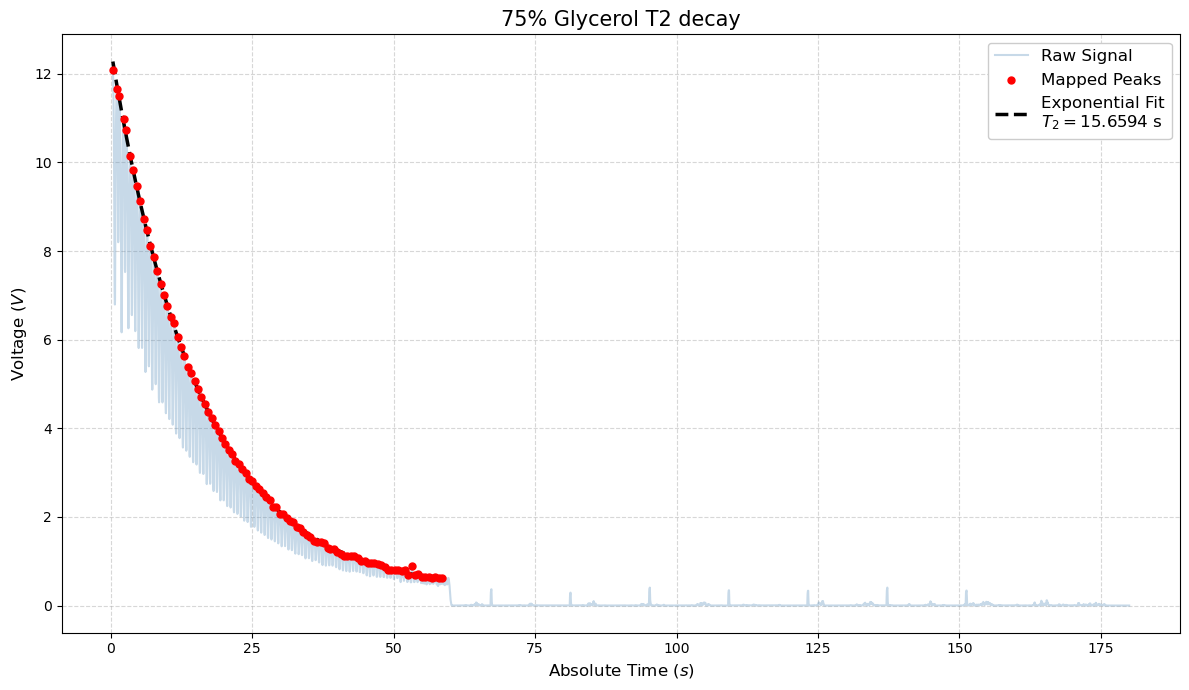

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

# 1. Load the file and clean columns
file = r"C:\Users\Student\OneDrive - University of Cambridge\Desktop\E2\100% glycerol\T_2 csv 1.csv"
data = pd.read_csv(file, encoding='windows-1252', skiprows=1)

# FIXED: Now strictly expects and names the two available columns
data.columns = ['time', 'voltage']

# Convert to numeric
data['voltage'] = pd.to_numeric(data['voltage'], errors='coerce')
data['time'] = pd.to_numeric(data['time'], errors='coerce')
data = data.dropna(subset=['time', 'voltage'])

# 2. Find the global maximum to set the starting point
vmaxid = data['voltage'].idxmax()
t_start_analysis = data.loc[vmaxid, 'time']

# 3. Estimate period 
post_peak_data = data.loc[vmaxid:].copy()
min_prominence = post_peak_data['voltage'].max() * 0.20 
peaks_rough, _ = find_peaks(post_peak_data['voltage'], distance=20, prominence=min_prominence)
t_peaks = post_peak_data.iloc[peaks_rough]['time'].values
period_guess = np.mean(np.diff(t_peaks[:5])) 

# 4. Sequential Windowed Search
refined_times = []
refined_voltages = []
window_half_width = period_guess * 0.25

current_time_guess = t_start_analysis

for i in range(98):
    t_start = current_time_guess - window_half_width
    t_end = current_time_guess + window_half_width
    
    window = data[(data['time'] >= t_start) & (data['time'] <= t_end)]
    
    if not window.empty:
        max_idx = window['voltage'].idxmax()
        actual_max_v = window.loc[max_idx, 'voltage']
        actual_max_t = window.loc[max_idx, 'time']
        
        refined_times.append(actual_max_t)
        refined_voltages.append(actual_max_v)
        
        current_time_guess = actual_max_t + period_guess
    else:
        current_time_guess += period_guess

peak_results = pd.DataFrame({'Time': refined_times, 'Voltage': refined_voltages})
print(f"Calculated True Period: {period_guess:.4f} seconds")

# 5. Define the mathematical decay function
def decay_func(t, A, T_2, C):
    return A * np.exp(-t / T_2) + C

# 6. Prepare data for Curve Fit (Shifted to t=0)
t_zeroed = peak_results['Time'] - peak_results['Time'].iloc[0]
v_data = peak_results['Voltage']

# Initial guesses and curve fitting
A_guess = v_data.max() - v_data.min()
T2_guess = t_zeroed.iloc[-1] / 3.0  
C_guess = v_data.min()
initial_guess = [A_guess, T2_guess, C_guess]

popt, pcov = curve_fit(decay_func, t_zeroed, v_data, p0=initial_guess)
A_fit, T2_fit, C_fit = popt

print(f"--- Fit Results ---")
print(f"Initial Amplitude (A): {A_fit:.4f} V")
print(f"Decay Factor (T_2):     {T2_fit:.4f} s")
print(f"Baseline Offset (C):   {C_fit:.4f} V")

# Generate smooth fit line
t_smooth_zeroed = np.linspace(t_zeroed.min(), t_zeroed.max(), 500)
v_fit_smooth = decay_func(t_smooth_zeroed, A_fit, T2_fit, C_fit)

# Shift smooth time back to absolute time for plotting alongside raw data
t_smooth_absolute = t_smooth_zeroed + peak_results['Time'].iloc[0]

# --- 7. The Unified Plot ---
plt.figure(figsize=(12, 7))

# Plot A: Raw underlying signal
plt.plot(data.loc[vmaxid:, 'time'], data.loc[vmaxid:, 'voltage'], 
         color='steelblue', alpha=0.3, label='Raw Signal')

# Plot B: The 99 mapped peaks
plt.scatter(peak_results['Time'], peak_results['Voltage'], 
            color='red', s=25, label='Mapped Peaks', zorder=5)

# Plot C: The smooth exponential curve fit
plt.plot(t_smooth_absolute, v_fit_smooth, 'k--', linewidth=2.5, 
         label=f'Exponential Fit\n$T_2 = {T2_fit:.4f}$ s')

# Formatting
plt.title('75% Glycerol T2 decay', fontsize=15)
plt.xlabel('Absolute Time ($s$)', fontsize=12)
plt.ylabel('Voltage ($V$)', fontsize=12)
plt.legend(fontsize=12, loc='upper right', framealpha=1.0) # Solid legend box so lines don't bleed through
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
